In [3]:
import random
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq
from scipy.stats import norm

In [4]:
# Simulatie: inslaglocatie van mortiergranaten
def point_of_impact(x):
    return lambda x: 15 / 92 * (4 - x ** 2 - 3 * x ** 4)

def cdf(x):
    return (15/92) * (4*x - x**3/3 - 3*x**5/5 + 46/15)

def inverse_cdf(u):
    # Solves the inverse CDF problem cdf(x) = u for a given probability u in [0, 1], where x can be between -1 and 1
    return brentq(lambda x: cdf(x) - u, -1, 1)

def mortar_grenades(n):
    u = np.random.uniform(0, 1, n)
    return np.array([
        brentq(lambda x: cdf(x) - ui, -1, 1)
        for ui in u
    ])

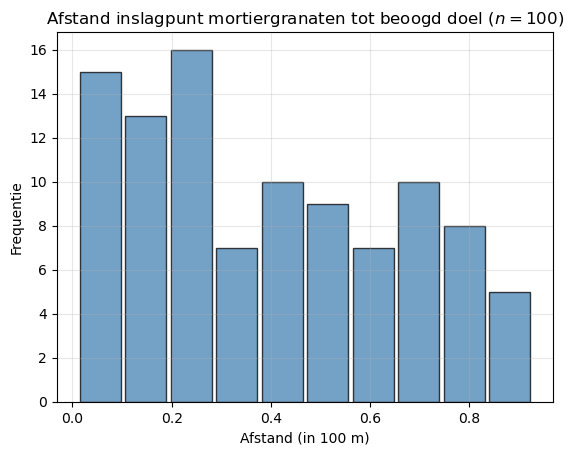

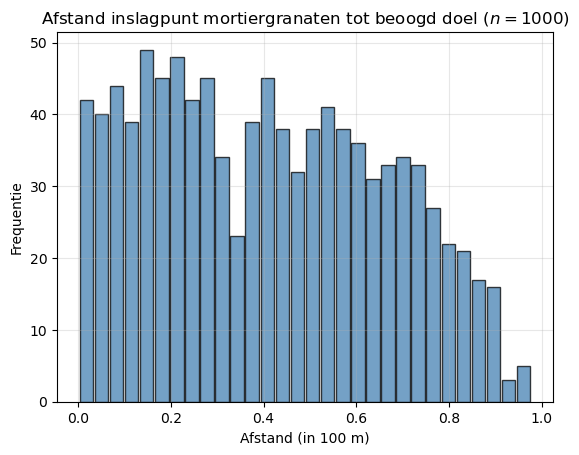

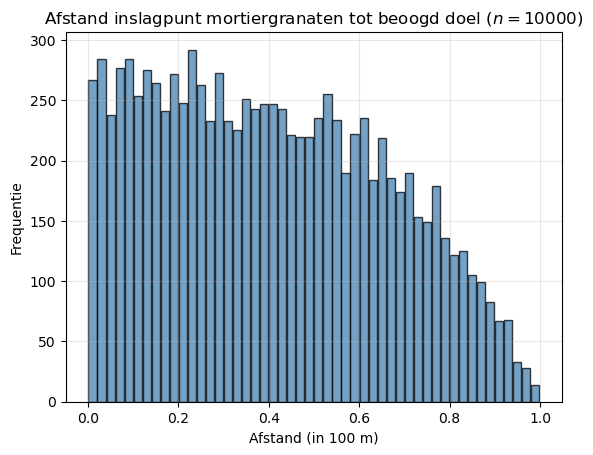

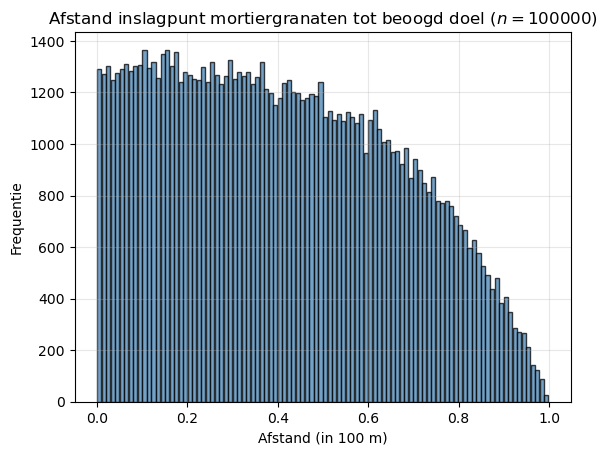

In [5]:
for (n_samples, bins) in [(100, 10), (1000, 30), (10000, 50), (100000, 100)]:
    samples = mortar_grenades(n_samples)
    
    fig, ax = plt.subplots()
    
    # Histogram of the generated samples
    ax.hist(
        np.abs(samples),
        bins=bins,#int(np.sqrt(n_samples)),
        density=False,
        color="steelblue",
        edgecolor="black",
        linewidth=1.0,
        alpha=0.75,
        rwidth=0.9,
    )
    
    # Theoretical PDF
    # x = np.linspace(0, 1, 1_000)
    # pdf = 0.065 * n_samples * abs(15/92 * (4 - x**2 - 3*x**4))
    
    # plt.plot(x, pdf, 'r-', linewidth=2, label="Theoretical PDF")
    
    ax.set_xlabel("Afstand (in 100 m)")
    ax.set_ylabel("Frequentie")
    ax.set_title(f"Afstand inslagpunt mortiergranaten tot beoogd doel ($n={n_samples}$)")
    # plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(f"../figures/2_mortar_grenades_hist_n={n_samples}_bins={bins}.png")

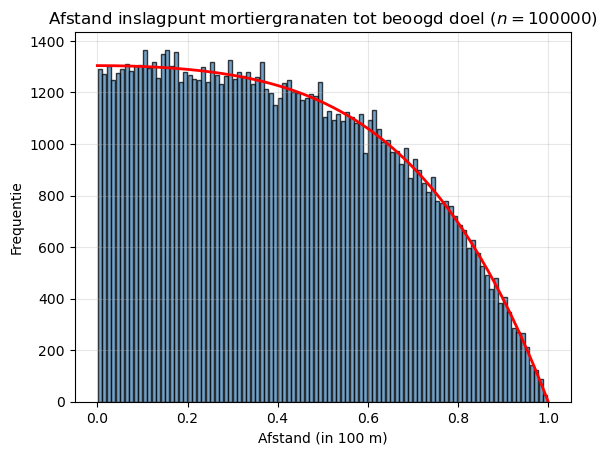

In [6]:
fig, ax = plt.subplots()
x = np.linspace(0, 1, 1_000)
pdf = 0.02 * n_samples * abs(15/92 * (4 - x**2 - 3*x**4))
ax.hist(
    np.abs(samples),
    bins=bins,#int(np.sqrt(n_samples)),
    density=False,
    color="steelblue",
    edgecolor="black",
    linewidth=1.0,
    alpha=0.75,
    rwidth=0.9,
)
ax.plot(x, pdf, 'r-', linewidth=2, label="Theoretical PDF")
ax.set_xlabel("Afstand (in 100 m)")
ax.set_ylabel("Frequentie")
ax.set_title(f"Afstand inslagpunt mortiergranaten tot beoogd doel ($n={n_samples}$)")

# plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f"../figures/2_mortar_grenades_hist_n={n_samples}_bins={bins}_with_pdf.png")

# Verschillende normale verdelingen

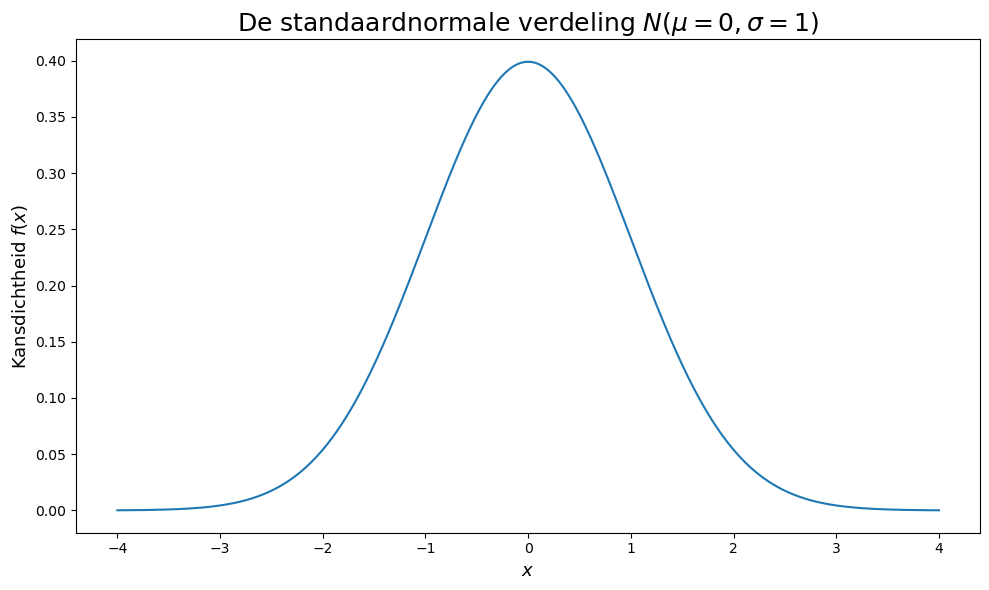

In [26]:
fig, ax = plt.subplots(figsize=(10,6))

xmin, xmax, npoints = -4, 4, 1_000
x = np.linspace(xmin, xmax, npoints)

mu, sigma = 0, 1
ax.plot(x, norm.pdf(x, loc=mu, scale=sigma))
ax.set_xlabel(f"$x$", fontsize=13)
ax.set_ylabel("Kansdichtheid $f(x)$", fontsize=13)
ax.set_title(f"De standaardnormale verdeling $N(\\mu={mu}, \\sigma={sigma})$", fontsize=18)

# ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(f"../figures/2_standard_normal_distribution.png")

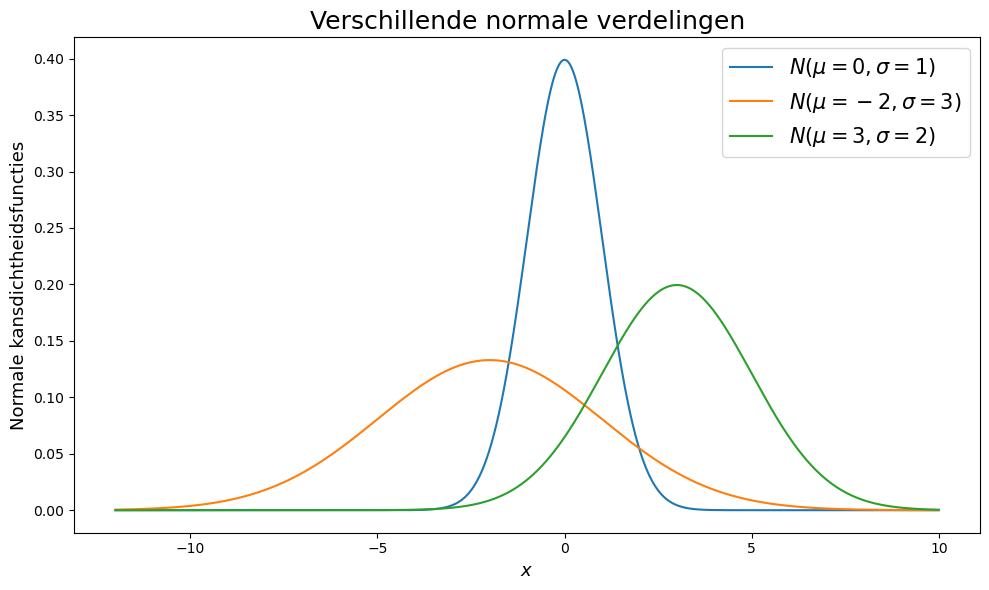

In [28]:
fig, ax = plt.subplots(figsize=(10,6))

xmin, xmax, npoints = -12, 10, 1_000
x = np.linspace(xmin, xmax, npoints)

for (mu, sigma) in (0, 1), (-2, 3), (3, 2):
    ax.plot(x, norm.pdf(x, loc=mu, scale=sigma),label=f"$N(\\mu={mu}, \\sigma={sigma})$")
    ax.set_xlabel(f"$x$", fontsize=13)
    ax.set_ylabel("Normale kansdichtheidsfuncties", fontsize=13)
    ax.set_title("Verschillende normale verdelingen", fontsize=18)

ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(f"../figures/2_normal_distribution.png")